# Exoplanet Data Grounding and EDA

This notebook is the starting point for the project. It loads the two catalogs, groups features into rough scientific families, and measures the main implementation risks: missing data, uncertainty columns, and detection-method bias.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(context="notebook", style="whitegrid")

DATA_DIR = Path.cwd() / "data"
EU_PATH = DATA_DIR / "exoplanet.eu_catalog_28-05-26_22_04_09.csv"
NASA_PATH = DATA_DIR / "PS_2026.05.28_13.08.08.csv"

EU_PATH, NASA_PATH

(PosixPath('/opt/exoplanet-analysis/data/exoplanet.eu_catalog_28-05-26_22_04_09.csv'),
 PosixPath('/opt/exoplanet-analysis/data/PS_2026.05.28_13.08.08.csv'))

In [8]:
eu_df = pd.read_csv(EU_PATH, low_memory=False)
nasa_df = pd.read_csv(NASA_PATH, comment="#", low_memory=False)

print(f"exoplanet.eu shape: {eu_df.shape}")
print(f"NASA shape: {nasa_df.shape}")

exoplanet.eu shape: (6434, 98)
NASA shape: (39876, 289)


In [9]:
pd.DataFrame(
    {
        "dataset": ["eu", "nasa"],
        "n_rows": [len(eu_df), len(nasa_df)],
        "n_columns": [eu_df.shape[1], nasa_df.shape[1]],
        "sample_columns": [
            ", ".join(eu_df.columns[:8]),
            ", ".join(nasa_df.columns[:8]),
        ],
    }
)

,dataset,n_rows,n_columns,sample_columns
0,eu,6434,98,"name, planet_status, mass, mass_error_min, mas..."
1,nasa,39876,289,"rowid, pl_name, hostname, pl_letter, hd_name, ..."


In [10]:
def group_columns(columns):
    groups = {
        "planet": [],
        "star": [],
        "orbit_timing": [],
        "metadata": [],
        "uncertainty": [],
        "other": [],
    }

    metadata_names = {
        "name",
        "planet_status",
        "publication",
        "detection_type",
        "updated",
        "discovered",
    }

    for col in columns:
        if "error" in col or col.endswith(("err1", "err2", "lim")):
            groups["uncertainty"].append(col)
        elif col.startswith(("star_", "st_", "sy_")) or col in {
            "star_name",
            "hostname",
        }:
            groups["star"].append(col)
        elif col.startswith(
            (
                "orbital_",
                "semi_",
                "eccentricity",
                "inclination",
                "omega",
                "tperi",
                "tconj",
                "tzero",
                "pl_orb",
                "pl_tran",
                "pl_rva",
                "pl_occ",
            )
        ):
            groups["orbit_timing"].append(col)
        elif (
            col in metadata_names
            or "method" in col
            or "status" in col
            or "publication" in col
            or "refname" in col
        ):
            groups["metadata"].append(col)
        elif col.startswith(
            ("mass", "radius", "temp", "pl_", "hot_", "geo", "log_g")
        ) or col in {"mass", "radius"}:
            groups["planet"].append(col)
        else:
            groups["other"].append(col)

    return {name: values for name, values in groups.items() if values}


eu_groups = group_columns(eu_df.columns)
nasa_groups = group_columns(nasa_df.columns)

pd.DataFrame(
    {
        "eu_columns": {key: len(value) for key, value in eu_groups.items()},
        "nasa_columns": {key: len(value) for key, value in nasa_groups.items()},
    }
).fillna(0).astype(int)

,eu_columns,nasa_columns
planet,10,28
star,11,45
orbit_timing,10,11
metadata,6,3
uncertainty,48,166
other,13,36


In [11]:
eu_missingness = (
    eu_df.isna().mean().sort_values(ascending=False).rename("missing_fraction")
)
eu_missingness.head(20).to_frame()

,missing_fraction
hot_point_lon,0.999534
star_magnetic_field,0.999067
geometric_albedo_error_min,0.997513
geometric_albedo_error_max,0.997513
geometric_albedo,0.997358
log_g,0.996270
tzero_vr_error_max,0.995026
tzero_vr_error_min,0.995026
tzero_vr,0.994716
temp_measured,0.994716


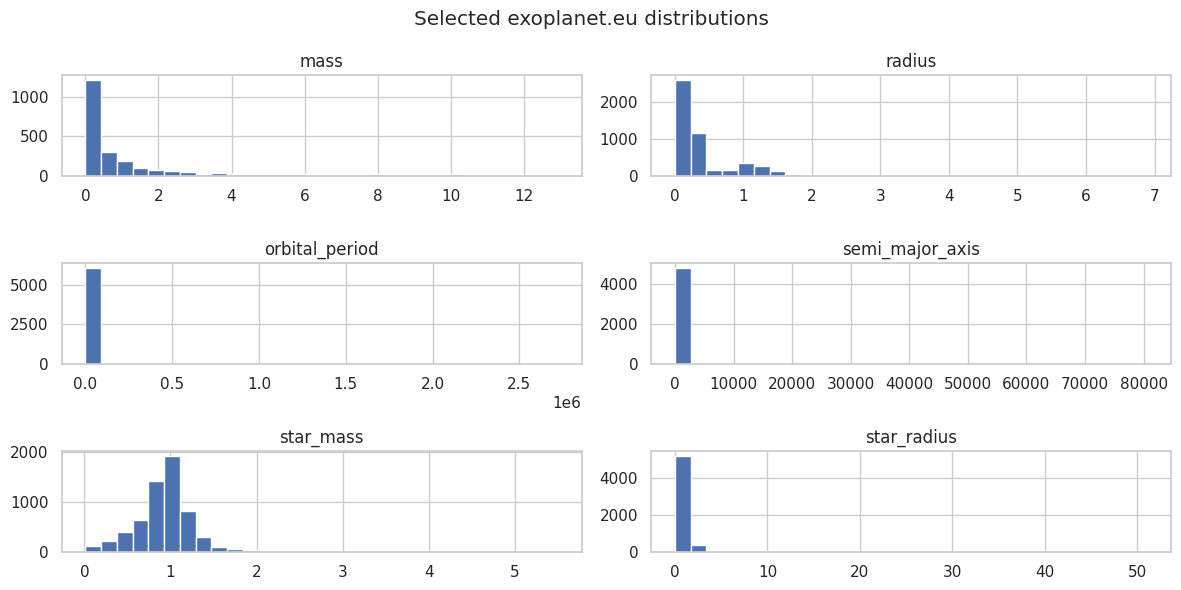

In [12]:
plot_columns = [
    col
    for col in [
        "mass",
        "radius",
        "orbital_period",
        "semi_major_axis",
        "star_mass",
        "star_radius",
    ]
    if col in eu_df.columns
]
eu_df[plot_columns].hist(figsize=(12, 6), bins=30)
plt.suptitle("Selected exoplanet.eu distributions")
plt.tight_layout()